# Squash Video Classification: ResNet-18 + GRU

This notebook trains a **video-level, three-class classifier** for:

- `no_let`
- `stroke`
- `yes_let`

Each video is treated as one training example. The notebook samples frames in temporal order, extracts frozen features with an ImageNet-pretrained ResNet, and trains a GRU to classify the complete sequence.

**Important:** the 80/20 split is performed on complete video files *before* frame extraction. Frames from one video can therefore never appear in both train and test sets.

Run the cells from top to bottom. By default, the notebook expects this structure relative to the notebook's working directory:

```text
AI project/
├── squash_video_classification.ipynb
├── dataset/
│   ├── no_let/
│   ├── stroke/
│   └── yes_let/
└── runs/                 # created automatically
```

The file scanner accepts `.mov` and `.mp4` (as well as `.m4v`, `.avi`, and `.mkv`) so clips are not accidentally ignored if their extensions differ.

## 1. Kaggle environment check

Kaggle already provides CUDA-enabled PyTorch and the common scientific Python packages. Do not reinstall `torch` or `torchvision` here, because doing so can replace the compatible CUDA build. The next code cell only checks the installed versions.


In [1]:
import torch
import torchvision
import cv2
import sklearn

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("OpenCV:", cv2.__version__)
print("scikit-learn:", sklearn.__version__)


PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
OpenCV: 4.14.0
scikit-learn: 1.6.1


## 2. Imports and configuration

The dataset is attached as a Kaggle input. Its path is read-only. All generated files are saved under `/kaggle/working`, which is the writable output area.


In [2]:
from pathlib import Path
import os
import csv
import json
import math
import hashlib
import random
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)

# Kaggle input path copied from the attached dataset shown in your screenshot.
PROJECT_DIR = Path("/kaggle/working")
DATA_DIR = Path("/kaggle/input/datasets/a5traeus/squash-fouls/dataset")
OUTPUT_DIR = Path("/kaggle/working/runs/squash_gru")

# Training configuration
TEST_SIZE = 0.20
NUM_FRAMES = 24
BACKBONE_NAME = "resnet50"     # "resnet18" or "resnet50"
GRU_HIDDEN_SIZE = 128
DROPOUT = 0.35
EPOCHS = 50
BATCH_SIZE = 8                 # batch of videos for GRU training
FEATURE_BATCH_SIZE = 16        # batch of frames through the CNN; safe starting point for a Kaggle GPU
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
RANDOM_SEED = 42
NUM_WORKERS = 0                # feature tensors are already cached in memory; 0 is reliable on Kaggle

# Support both extensions seen in the supplied file listing, plus common variants.
VIDEO_EXTENSIONS = {".mov", ".mp4", ".m4v", ".avi", ".mkv"}

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)

Project directory: /kaggle/working
Dataset directory: /kaggle/input/datasets/a5traeus/squash-fouls/dataset
Output directory: /kaggle/working/runs/squash_gru


## 3. Select the Kaggle GPU and set random seeds

The notebook selects CUDA automatically. This cell also prints the GPU model and stops with a clear message if the Kaggle session is still running on CPU.


In [3]:
def set_seed(seed: int = RANDOM_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def choose_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if hasattr(torch, "xpu") and torch.xpu.is_available():
        return torch.device("xpu")
    return torch.device("cpu")


set_seed()
torch.set_num_threads(max(1, min(8, os.cpu_count() or 4)))
DEVICE = choose_device()
print("PyTorch version:", torch.__version__)
print("Selected device:", DEVICE)
if DEVICE.type != "cuda":
    raise RuntimeError(
        "CUDA GPU not detected. In Kaggle, open Notebook > Session options, "
        "set Accelerator to a GPU, wait for the session to restart, then rerun this cell."
    )
print("GPU name:", torch.cuda.get_device_name(0))
print("CUDA version used by PyTorch:", torch.version.cuda)
print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / (1024**3), 2))

PyTorch version: 2.11.0+cu130
Selected device: cuda
GPU name: Tesla T4
CUDA version used by PyTorch: 13.0
GPU memory (GB): 14.56


## 4. Discover videos and inspect class balance

Every immediate subfolder inside `dataset` is treated as a class. The folder name becomes the label. The scanner reports counts by class and extension so missing or unsupported files are visible before training.

In [4]:
def discover_videos(data_dir: Path):
    if not data_dir.exists() or not data_dir.is_dir():
        raise FileNotFoundError(
            f"Dataset folder not found: {data_dir}\n"
            "Expected dataset/<class_name>/<video files>. "
            "Update DATA_DIR in the configuration cell if needed."
        )

    class_folders = sorted(
        folder for folder in data_dir.iterdir()
        if folder.is_dir() and not folder.name.startswith(".")
    )

    class_names = []
    video_paths = []
    labels = []
    summary_rows = []

    for folder in class_folders:
        clips = sorted(
            path for path in folder.iterdir()
            if path.is_file() and path.suffix.lower() in VIDEO_EXTENSIONS
        )
        if not clips:
            print(f"WARNING: no supported video files found in {folder.name!r}")
            continue

        class_index = len(class_names)
        class_names.append(folder.name)
        video_paths.extend(clips)
        labels.extend([class_index] * len(clips))

        extension_counts = Counter(path.suffix.lower() for path in clips)
        summary_rows.append({
            "class": folder.name,
            "videos": len(clips),
            "extensions": dict(extension_counts),
        })

    if len(class_names) < 2:
        raise RuntimeError(
            f"Found only {len(class_names)} class folder(s) containing supported videos. "
            f"Supported extensions: {sorted(VIDEO_EXTENSIONS)}"
        )

    return video_paths, class_names, labels, summary_rows


video_paths, class_names, labels, class_summary = discover_videos(DATA_DIR)
summary_df = pd.DataFrame(class_summary)
display(summary_df)

print(f"Total videos: {len(video_paths)}")
print("Class-to-index mapping:", {name: i for i, name in enumerate(class_names)})

,class,videos,extensions
0,no_let,80,{'.mov': 80}
1,stroke,104,"{'.mp4': 88, '.mov': 16}"
2,yes_let,88,{'.mov': 88}


Total videos: 272
Class-to-index mapping: {'no_let': 0, 'stroke': 1, 'yes_let': 2}


## 5. Inspect sample video metadata

This checks whether OpenCV can open at least one file from each class and reports its resolution, frame rate, frame count, and approximate duration. If a video cannot be opened, verify that its codec is supported by your OpenCV/FFmpeg installation.

In [5]:
def inspect_video(video_path: Path):
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        return {
            "video": str(video_path), "opened": False,
            "width": None, "height": None, "fps": None,
            "frame_count": None, "duration_seconds": None,
        }

    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = float(cap.get(cv2.CAP_PROP_FPS))
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()

    duration = frame_count / fps if fps > 0 and frame_count > 0 else None
    return {
        "video": str(video_path), "opened": True,
        "width": width, "height": height, "fps": fps,
        "frame_count": frame_count, "duration_seconds": duration,
    }


sample_rows = []
for class_name in class_names:
    class_files = [p for p, y in zip(video_paths, labels) if class_names[y] == class_name]
    sample_rows.append(inspect_video(class_files[0]))

metadata_df = pd.DataFrame(sample_rows)
display(metadata_df)
if not metadata_df["opened"].all():
    print("WARNING: At least one sample video could not be opened. Resolve codec/file issues before continuing.")

,video,opened,width,height,fps,frame_count,duration_seconds
0,/kaggle/input/datasets/a5traeus/squash-fouls/d...,True,1920,1080,30.0,166,5.533333
1,/kaggle/input/datasets/a5traeus/squash-fouls/d...,True,1920,1080,60.0,252,4.200000
2,/kaggle/input/datasets/a5traeus/squash-fouls/d...,True,1080,1350,30.0,145,4.833333


## 6. Make the stratified 80/20 split at video level

The split is done using video paths and their folder labels. Unequal class sizes are supported. With stratification, each class is represented in both splits, with exact percentages subject to integer rounding.

In [6]:
if not 0.05 <= TEST_SIZE <= 0.50:
    raise ValueError("TEST_SIZE should be between 0.05 and 0.50.")

label_array = np.asarray(labels, dtype=np.int64)
unique_labels, class_counts = np.unique(label_array, return_counts=True)
if np.any(class_counts < 2):
    too_small = {
        class_names[int(label)]: int(count)
        for label, count in zip(unique_labels, class_counts) if count < 2
    }
    raise ValueError(f"Every class needs at least two videos for stratified splitting: {too_small}")

n_test = math.ceil(len(video_paths) * TEST_SIZE)
n_train = len(video_paths) - n_test
if n_test < len(class_names) or n_train < len(class_names):
    raise ValueError("Not enough total videos to place every class in both train and test splits.")

train_paths, test_paths, train_labels, test_labels = train_test_split(
    video_paths,
    label_array.tolist(),
    test_size=TEST_SIZE,
    random_state=RANDOM_SEED,
    stratify=label_array,
)

split_rows = []
for split_name, paths, split_labels in [
    ("train", train_paths, train_labels),
    ("test", test_paths, test_labels),
]:
    for path, label in zip(paths, split_labels):
        split_rows.append({
            "split": split_name,
            "video_path": str(path.relative_to(DATA_DIR)),
            "class_name": class_names[int(label)],
            "label": int(label),
        })

split_df = pd.DataFrame(split_rows)
split_df.to_csv(OUTPUT_DIR / "data_split.csv", index=False)

split_counts = pd.crosstab(split_df["class_name"], split_df["split"])
for column in ["train", "test"]:
    if column not in split_counts.columns:
        split_counts[column] = 0
split_counts = split_counts[["train", "test"]]
split_counts["total"] = split_counts.sum(axis=1)
display(split_counts)
print(f"Train videos: {len(train_paths)} | Test videos: {len(test_paths)}")
print("Saved split manifest:", OUTPUT_DIR / "data_split.csv")

split,train,test,total
class_name,,,
no_let,64,16,80
stroke,83,21,104
yes_let,70,18,88


Train videos: 217 | Test videos: 55
Saved split manifest: /kaggle/working/runs/squash_gru/data_split.csv


## 7. Sample a fixed number of ordered frames from each video

Frames are sampled uniformly from the start to the end of each clip. If a clip contains fewer readable frames than requested, the available frames are repeated at evenly spaced positions so every video produces a sequence of exactly `NUM_FRAMES` frames.

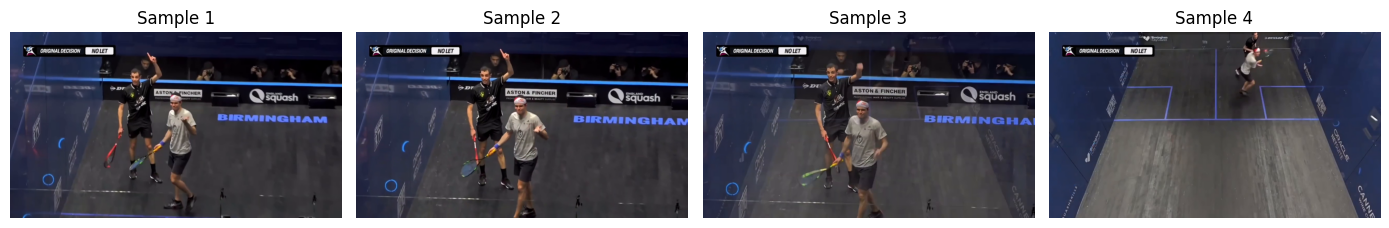

Frame sampler returned 24 frames for 1.mov


In [7]:
def sample_video_frames(video_path: Path, num_frames: int = NUM_FRAMES):
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(
            f"OpenCV could not open {video_path}. Check the file and codec/FFmpeg support."
        )

    frames = []
    try:
        frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        if frame_count > 0:
            indices = np.rint(np.linspace(0, max(frame_count - 1, 0), num_frames)).astype(int)
            for frame_index in indices:
                cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_index))
                ok, bgr = cap.read()
                if ok and bgr is not None:
                    frames.append(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
        else:
            # Fallback for containers that do not report frame count: reservoir sample
            # decoded frames, then restore their original time order.
            rng = np.random.default_rng(RANDOM_SEED)
            reservoir = []
            frame_index = 0
            while True:
                ok, bgr = cap.read()
                if not ok:
                    break
                rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
                if frame_index < num_frames:
                    reservoir.append((frame_index, rgb))
                else:
                    chosen = int(rng.integers(0, frame_index + 1))
                    if chosen < num_frames:
                        reservoir[chosen] = (frame_index, rgb)
                frame_index += 1
            reservoir.sort(key=lambda item: item[0])
            frames = [frame for _, frame in reservoir]
    finally:
        cap.release()

    if not frames:
        raise RuntimeError(f"No readable frames found in {video_path}")

    if len(frames) != num_frames:
        indices = np.rint(np.linspace(0, len(frames) - 1, num_frames)).astype(int)
        frames = [frames[int(i)] for i in indices]

    return frames


# Quick visual check on one video before processing the whole dataset.
preview_frames = sample_video_frames(video_paths[0], NUM_FRAMES)
fig, axes = plt.subplots(1, min(4, NUM_FRAMES), figsize=(14, 3))
for ax, frame, frame_no in zip(np.atleast_1d(axes), preview_frames[:4], range(1, 5)):
    ax.imshow(frame)
    ax.set_title(f"Sample {frame_no}")
    ax.axis("off")
plt.tight_layout()
plt.show()
print(f"Frame sampler returned {len(preview_frames)} frames for {video_paths[0].name}")

## 8. Build the pretrained CNN feature extractor

The ResNet classification layer is removed. Each sampled frame is converted into a feature vector (512 dimensions for ResNet-18, 2048 for ResNet-50). The CNN is frozen: only the GRU and final classifier are trained. The first run may download pretrained ImageNet weights.

In [8]:
def build_frame_encoder(backbone_name: str, device: torch.device):
    if backbone_name == "resnet18":
        weights = models.ResNet18_Weights.DEFAULT
        full_model = models.resnet18(weights=weights)
    elif backbone_name == "resnet50":
        weights = models.ResNet50_Weights.DEFAULT
        full_model = models.resnet50(weights=weights)
    else:
        raise ValueError("BACKBONE_NAME must be 'resnet18' or 'resnet50'.")

    feature_dim = full_model.fc.in_features
    encoder = nn.Sequential(*list(full_model.children())[:-1])
    encoder.eval().to(device)
    for parameter in encoder.parameters():
        parameter.requires_grad = False

    preprocess = weights.transforms()
    return encoder, preprocess, feature_dim, str(type(weights).__name__) + ".DEFAULT"


encoder, preprocess, FEATURE_DIM, BACKBONE_WEIGHTS = build_frame_encoder(BACKBONE_NAME, DEVICE)
print("Backbone:", BACKBONE_NAME)
print("Feature dimension:", FEATURE_DIM)
print("CNN parameters trainable:", any(p.requires_grad for p in encoder.parameters()))

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 180MB/s] 


Backbone: resnet50
Feature dimension: 2048
CNN parameters trainable: False


## 9. Extract and cache one feature sequence per video

A video becomes a tensor with shape `[NUM_FRAMES, FEATURE_DIM]`. Cached `.pt` files avoid repeating the expensive CNN pass when you rerun later cells with the same videos, backbone, and frame count. The cache key also changes if a source video is modified.

In [9]:
CACHE_DIR = OUTPUT_DIR / "feature_cache" / f"{BACKBONE_NAME}_{NUM_FRAMES}frames"
CACHE_DIR.mkdir(parents=True, exist_ok=True)


def make_cache_path(video_path: Path):
    stat = video_path.stat()
    relative_path = str(video_path.resolve().relative_to(DATA_DIR.resolve()))
    signature = (
        f"{DATA_DIR.resolve()}|{relative_path}|{stat.st_size}|{stat.st_mtime_ns}|"
        f"{BACKBONE_NAME}|{NUM_FRAMES}|imagenet-default"
    )
    digest = hashlib.sha1(signature.encode("utf-8")).hexdigest()
    return CACHE_DIR / f"{digest}.pt"


def extract_or_load_video_features(paths):
    feature_map = {}

    for video_number, video_path in enumerate(paths, start=1):
        cache_path = make_cache_path(video_path)

        if cache_path.exists():
            try:
                try:
                    features = torch.load(cache_path, map_location="cpu", weights_only=True)
                except TypeError:
                    features = torch.load(cache_path, map_location="cpu")
                if isinstance(features, torch.Tensor) and tuple(features.shape) == (NUM_FRAMES, FEATURE_DIM):
                    feature_map[video_path] = features.float()
                    print(f"[{video_number}/{len(paths)}] cache hit: {video_path.name}")
                    continue
            except Exception as exc:
                print(f"Cache read failed for {video_path.name}: {exc}. Recomputing.")

        frames = sample_video_frames(video_path, NUM_FRAMES)
        frame_tensors = torch.stack([
            preprocess(Image.fromarray(frame)) for frame in frames
        ])

        feature_batches = []
        with torch.no_grad():
            for start in range(0, len(frame_tensors), FEATURE_BATCH_SIZE):
                batch = frame_tensors[start:start + FEATURE_BATCH_SIZE].to(DEVICE)
                batch_features = encoder(batch).flatten(1)
                feature_batches.append(batch_features.cpu())

        features = torch.cat(feature_batches, dim=0).float()
        expected_shape = (NUM_FRAMES, FEATURE_DIM)
        if tuple(features.shape) != expected_shape:
            raise RuntimeError(
                f"Unexpected feature shape for {video_path.name}: {tuple(features.shape)}; "
                f"expected {expected_shape}"
            )

        torch.save(features, cache_path)
        feature_map[video_path] = features
        print(f"[{video_number}/{len(paths)}] extracted: {video_path.name}")

    return feature_map


# Extract features for all videos. This does not train on or use test labels.
all_video_paths = list(train_paths) + list(test_paths)
feature_map = extract_or_load_video_features(all_video_paths)

# The frozen CNN is no longer needed for GRU training.
del encoder
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

print("Feature sequences cached:", len(feature_map))
print("Feature shape per video:", tuple(next(iter(feature_map.values())).shape))

[1/272] extracted: 4.mp4
[2/272] extracted: 87.mp4
[3/272] extracted: 40.mov
[4/272] extracted: 54.mov
[5/272] extracted: 77.mp4
[6/272] extracted: 86.mov
[7/272] extracted: 17.mp4
[8/272] extracted: 51.mov
[9/272] extracted: 55.mov
[10/272] extracted: 53.mov
[11/272] extracted: 60.mov
[12/272] extracted: 49.mov
[13/272] extracted: 13.mp4
[14/272] extracted: 95.mp4
[15/272] extracted: 79.mov
[16/272] extracted: 88.mp4
[17/272] extracted: 7.mp4
[18/272] extracted: 33.mov
[19/272] extracted: 20.mp4
[20/272] extracted: 36.mov
[21/272] extracted: 91.mp4
[22/272] extracted: 1.mov
[23/272] extracted: 60.mov
[24/272] extracted: 32.mov
[25/272] extracted: 44.mov
[26/272] extracted: 20.mov
[27/272] extracted: 46.mov
[28/272] extracted: 32.mp4
[29/272] extracted: 69.mov
[30/272] extracted: 2.mp4
[31/272] extracted: 50.mov
[32/272] extracted: 48.mov
[33/272] extracted: 71.mov
[34/272] extracted: 67.mov
[35/272] extracted: 78.mov
[36/272] extracted: 12.mov
[37/272] extracted: 39.mp4
[38/272] extra

## 10. Create GRU datasets and handle class imbalance

Each dataset item is one video sequence and one video-level label. Inverse-frequency class weights are used in the loss so classes with fewer training videos are not automatically overwhelmed by larger classes.

In [10]:
def make_video_tensor_dataset(paths, split_labels, features_by_path):
    feature_tensor = torch.stack([features_by_path[path] for path in paths]).float()
    label_tensor = torch.tensor(split_labels, dtype=torch.long)
    return TensorDataset(feature_tensor, label_tensor)


train_dataset = make_video_tensor_dataset(train_paths, train_labels, feature_map)
test_dataset = make_video_tensor_dataset(test_paths, test_labels, feature_map)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)

train_class_counts = np.bincount(np.asarray(train_labels), minlength=len(class_names))
if np.any(train_class_counts == 0):
    raise RuntimeError("At least one class has no training videos. Cannot train classifier.")

class_weights = len(train_labels) / (len(class_names) * train_class_counts.astype(np.float32))
class_weight_tensor = torch.tensor(class_weights, dtype=torch.float32)

print("Training videos by class:", dict(zip(class_names, train_class_counts.tolist())))
print("Loss weights by class:", dict(zip(class_names, class_weights.round(3).tolist())))
print("Train tensor shape:", tuple(train_dataset.tensors[0].shape))
print("Test tensor shape:", tuple(test_dataset.tensors[0].shape))

Training videos by class: {'no_let': 64, 'stroke': 83, 'yes_let': 70}
Loss weights by class: {'no_let': 1.1299999952316284, 'stroke': 0.8709999918937683, 'yes_let': 1.0329999923706055}
Train tensor shape: (217, 24, 2048)
Test tensor shape: (55, 24, 2048)


## 11. Define the GRU video classifier

The GRU receives frame features in chronological order. Its final hidden state is used as the representation of the whole video, then a fully connected layer produces three class logits.

In [11]:
class GRUVideoClassifier(nn.Module):
    def __init__(self, feature_dim, hidden_size, num_classes, dropout):
        super().__init__()
        self.gru = nn.GRU(
            input_size=feature_dim,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True,
            bidirectional=False,
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # x: [batch_size, time_steps, feature_dim]
        _, hidden = self.gru(x)
        video_representation = hidden[-1]
        return self.classifier(self.dropout(video_representation))


model = GRUVideoClassifier(
    feature_dim=FEATURE_DIM,
    hidden_size=GRU_HIDDEN_SIZE,
    num_classes=len(class_names),
    dropout=DROPOUT,
).to(DEVICE)

print(model)

GRUVideoClassifier(
  (gru): GRU(2048, 128, batch_first=True)
  (dropout): Dropout(p=0.35, inplace=False)
  (classifier): Linear(in_features=128, out_features=3, bias=True)
)
